# Topic 8 - Advanced Data Visualisation

---
**Note: Content extracted from CM3005 course materials (available via Coursera)**

---

---

**Topic Learning Objectives**:
1. Discuss the underpinning theory of graphs and networks
2. Use algorithms to traverse graphs and to identify shortest and optimal routes
3. Use the Python programming language and libraries such as Matplotlib and NetworkX to build and visualise networks
4. Use the acquired knowledge and skills to solve real-world network-related problems and to develop and visualise large and complex networks
5. Design and develop visualisation tools presenting large and multidimensional datasets
6. Evaluate visualisation approaches based on their aesthetic, usefulness and the ability to convey information
7. Work with datasets with various dimensions and sizes
8. Choose appropriate visualisation approaches based on the types of the data points

---

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 8.3 Visualising Multidimensional Data </h2>
</div>

### 8.3.1 Dimensions in Structured Data

- Multidimensional data combine data points from a wide range of data types organised in a single entity, called dataset
- Multidimensional datasets are expected to be 'information rich', but this might not always be true
- In most cases, datasets with multiple dimensions need pre-processing before visualising
- Multidimensional datasets are not necessarily large, although this is usually the case
- Structured data (datasets) are organised into rows and columns
    * A row represents the characteristics of a single object
    * A column represents a single characteristic of the objects
    * The dimensions of the datasets are represented by the number of columns
- Multidimensional datasets may contain different types of data, including ratios, intervals, and nominal data types

- Example: Dataset containing characteristics of 10 objects (vehicles)

  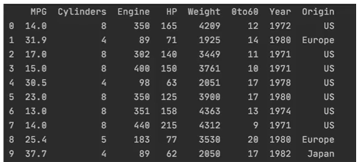


### 8.3.2 Heat Maps

- A graphical representation of multidimensional data
- Uses two-dimensional plane for visualisation
- Usually used for summarised information
- Data is presented colour-coded
- Rely solely on colour scheme to distinguish different data points or groups of data points
- Choosing correct colour scheme is critical for accurate and informative visualisation
- Common case for using heatmap is for 'mapping' numerical data on geographical map
    * Dataset needs to be accompanied with information about geographical location, e.g., longitude and latitude or other coordinate system used by the map
    * Usually used to indicate areas of concern, e.g., air pollution, extreme temperatures, property prices, others...
 

#### *Example 1: State Capitals*

- Consider a dataset that consists of the average temperatures for 7 state capitals
- There are tools (libraries) which can visualize datasets as heat maps.
    * Here, we will follow the steps necessary to develop heat map without using such tools (i.e., starting from scratch)
    * It will use 2 libraries: pandas and matplotlib

In [ ]:
# Step 0 -- Create the sample data

import pandas as pd
import os

# Define the data
data = {
    "City": ["Phoenix", "Little Rock", "Sacramento", "Denver", "Hartford", "Dover", "Tallahassee"],
    1:  [6, 4, 9, -2, -2, 2, 15],
    2:  [8, 6, 11, 1, 1, 4, 17],
    3:  [11, 12, 13, 5, 4, 6, 19],
    4:  [16, 17, 15, 9, 10, 12, 22],
    5:  [21, 21, 18, 14, 15, 17, 25],
    6:  [25, 25, 21, 20, 21, 22, 27],
    7:  [27, 28, 23, 23, 24, 25, 27],
    8:  [26, 27, 23, 23, 23, 24, 27],
    9:  [23, 23, 21, 10, 19, 20, 26],
    10: [17, 17, 17, 13, 12, 14, 23],
    11: [10, 11, 13, 10, 7, 8, 20],
    12: [6, 6, 9, -2, 1, 3, 17],
}

# Create DataFrame
df = pd.DataFrame(data)
df.set_index("City", inplace=True)

# Display the DataFrame
print(df)

# Optionally, save the data to a CSV file
if not os.path.exists('heatmap.csv'):
    df.to_csv('heatmap.csv')
    print("File saved.")
else:
    print("File exists. Not saved.")


In [ ]:
# Heatmap

# Source: CM3005 Data Science (Coursera)
# Week 16 Lab — "Coding Exercise: Heat Maps"
# Offered by University of London
# Accessed August 2025

# This example is for guidance only
# It generates a heatmap based on a dataset

import matplotlib.pyplot as plt
import pandas as pd

# This subroutine encapsulates the 'plot' method, as the most suitable for raster rendering
def DrawBox(x, y, size, r, g, b):
    for i in range(0, int(size)):
        if r > 255:
            r = int(255)
        if g > 255:
            g = int(255)
        if b > 255:
            b = int(255)
        plt.plot([x, x + size], [y + i, y + i], '#{:02x}{:02x}{:02x}'.format(r, g, b))


df = pd.read_csv('heatmap.csv')
print(df.head(7))
plt.axis([0, 800, 0, 500])  # format is [xmin, xmax, ymin, ymax]
plt.xticks([])
plt.yticks([])
plt.box(False)

# plt.axis('off')
BoxSize = int(40)
for i in range(0, df.shape[0]):
    for j in range(1, df.shape[1]):
        ColourCode = int(((df.values[i, j]+2)/30)*255)
        DrawBox(110+BoxSize*j, 300-BoxSize*i, BoxSize, ColourCode, 0, 0)
        OffsetX = int(15)
        OffsetY = int(12)
        plt.text(OffsetX+100+40*j, OffsetY+300-40*i, str(df.values[i, j]), color='white')

for i in range(0, 280):
    plt.plot([660, 680], [i + 60, i + 60], '#{:02x}{:02x}{:02x}'.format(int((i / 280) * 255), 0, 0))

plt.text(162, 20, 'J')
plt.text(192, 20, 'F')
plt.text(232, 20, 'M')
plt.text(272, 20, 'A')
plt.text(312, 20, 'M')
plt.text(352, 20, 'J')
plt.text(392, 20, 'J')
plt.text(432, 20, 'A')
plt.text(472, 20, 'S')
plt.text(512, 20, 'O')
plt.text(552, 20, 'N')
plt.text(592, 20, 'D')

plt.text(5, 315, df.values[0, 0])
plt.text(5, 275, df.values[1, 0])
plt.text(5, 235, df.values[2, 0])
plt.text(5, 195, df.values[3, 0])
plt.text(5, 155, df.values[4, 0])
plt.text(5, 115, df.values[5, 0])
plt.text(5, 75, df.values[6, 0])

plt.text(685, 55, '-2')
plt.text(685, 85, ' 0')
plt.text(685, 195, '15')
plt.text(685, 332, '28')

plt.show()


In [ ]:
# Heat Map (Alternative)

# Previous approach of building from scratch involved much manual computations
# and can be error-prone (dependent on actual data).

# Here we revisit the heat map generation using the seaborn library

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Read CSV and set first column as index
df = pd.read_csv("heatmap.csv", index_col=0)

# Rename columns (the remaining columns are months)
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
                'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

df.columns = month_labels

plt.figure(figsize=(12, 6))
# sns.heatmap(df, cmap='inferno', annot=True, fmt="d", cbar=True)
sns.heatmap(df, cmap='coolwarm', annot=True, fmt="d", cbar=True)

plt.title('Average Temperature by City and Month')
plt.xlabel('Month')
plt.ylabel('City')

plt.show()


#### *Example 2: Car Sales*

- A car sales company organized into calendar quarters
- The company needs to reach a specific number of sales to be profitable
- If a type of vehicle does not perform well in sales, the company needs to re-consider offering it in the future
- How a heat map would visualize the sales of the last 8 quarters?

In [ ]:
# Step 1 -- Create the sample data

# Assume that the range of sales is 0 to 10

import pandas as pd

# Define the data
data = {
    "Vehicle": ["SUV", "Coupe", "Sedan", "Hatchback", "Pickup"],
    "2018Q1": [7, 8, 4, 7, 2],
    "2018Q2": [6, 5, 8, 9, 1],
    "2018Q3": [5, 6, 7, 6, 4],
    "2018Q4": [5, 6, 6, 7, 4],
    "2019Q1": [7, 5, 8, 8, 5],
    "2019Q2": [6, 8, 7, 5, 5],
    "2019Q3": [4, 8, 7, 6, 6],
    "2019Q4": [1, 4, 3, 3, 2]
}

# Create DataFrame
df = pd.DataFrame(data)

# Display the DataFrame
print(df)

In [ ]:
# Step 2 -- Visualize the heat map by following the same steps from the previous example

# Note: We adjust the coordinates of objects and add x- and y-axis labels

# Function to draw a colored box (a heatmap cell)
def DrawBox(x, y, size, r, g, b):
    for i in range(0, int(size)):
        if r > 255:
            r = int(255)
        if g > 255:
            g = int(255)
        if b > 255:
            b = int(255)
        plt.plot([x, x+size], [y+i, y+i], '#{:02x}{:02x}{:02x}'.format(r, g, b))

# Plot setup
fig = plt.figure(figsize=(12, 6))
plt.axis([0, 500, 0, 400])
plt.axis('off')

# Layout configuration
BoxSize = int(50)
OffsetX = int(20)
OffsetY = int(15)

# Draw heatmap cells
for i in range(0, df.shape[0]):
    for j in range(1, df.shape[1]):
        ColourCode = int(((df.values[i,j])/10)*255)
        DrawBox(50+BoxSize*j, 300-BoxSize*i, BoxSize, ColourCode, 0, 0)
        plt.text(OffsetX+50+BoxSize*j, OffsetY+300-BoxSize*i, 
                 str(df.values[i,j]), 
                 color='white', fontsize=12)

# Add vehicle labels on y-axis
for i in range(df.shape[0]):
    vehicle_label = df.iloc[i, 0]
    y_pos = 300 - BoxSize * i + BoxSize / 2  # center of the row
    plt.text(50, y_pos, vehicle_label, 
             ha='right', va='center', 
             fontsize=12)

# Add quarter labels on x-axis
for j, quarter in enumerate(df.columns[1:], start=1):  # skip first column 'Vehicle'
    x_pos = 50 + BoxSize * j + BoxSize / 2
    y_pos = 300 - BoxSize * df.shape[0]  # position below heatmap
    plt.text(x_pos, y_pos, quarter,
             ha='right', va='top', 
             fontsize=12, rotation=45
    )

plt.title('Sales Heatmap', fontsize=15)
plt.tight_layout()
plt.show()

In [ ]:
# Step 3 - Target Threshold

# For every type of vehicle, there is a minimum target number of purchases per calendar quarter.
# If a vehicle performs between the target, the business will reconsider offering it
# The heat map can highlight vehicle types which fall below a certain threshold by changing 
# the base color

# Source code modifications required:
Threshold = int(3)
if df.values[i,j] > Threshold:
    DrawBox(50+BoxSize*j, 300-BoxSize*i, BoxSize, 0, 0, ColourCode)
if df.values[i,j] <= Threshold:
    DrawBox(50+BoxSize*j, 300-BoxSize*i, BoxSize, ColourCode, 0, 0)

# Note: Do not run this code cell

In [ ]:
# Step 4 -- Visualise heat map highlighting a threshold of 3 sales by changing base color

# We incorporate the changes into the code

# Function to draw a colored box (a heatmap cell)
def DrawBox(x, y, size, r, g, b):
    for i in range(0, int(size)):
        if r > 255:
            r = int(255)
        if g > 255:
            g = int(255)
        if b > 255:
            b = int(255)
        plt.plot([x, x+size], [y+i, y+i], '#{:02x}{:02x}{:02x}'.format(r, g, b))

# Plot setup
fig = plt.figure(figsize=(12, 6))
plt.axis([0, 500, 0, 400])
plt.axis('off')

# Layout configuration
BoxSize = int(50)
OffsetX = int(20)
OffsetY = int(15)

# Draw heatmap cells
Threshold = int(3)
for i in range(0, df.shape[0]):
    for j in range(1, df.shape[1]):
        ColourCode = int(((df.values[i,j])/10)*255)
        if df.values[i,j] > Threshold: 
            DrawBox(50+BoxSize*j, 300-BoxSize*i, BoxSize, 0, 0, ColourCode)
        if df.values[i,j] <= Threshold:
            DrawBox(50+BoxSize*j, 300-BoxSize*i, BoxSize, ColourCode, 0, 0)
        plt.text(OffsetX+50+BoxSize*j, OffsetY+300-BoxSize*i, 
                 str(df.values[i,j]), 
                 color='white', fontsize=12)

# Add vehicle labels on y-axis
for i in range(df.shape[0]):
    vehicle_label = df.iloc[i, 0]
    y_pos = 300 - BoxSize * i + BoxSize / 2  # center of the row
    plt.text(50, y_pos, vehicle_label, 
             ha='right', va='center', 
             fontsize=12)

# Add quarter labels on x-axis
for j, quarter in enumerate(df.columns[1:], start=1):  # skip first column 'Vehicle'
    x_pos = 50 + BoxSize * j + BoxSize / 2
    y_pos = 300 - BoxSize * df.shape[0]  # position below heatmap
    plt.text(x_pos, y_pos, quarter,
             ha='right', va='top', 
             fontsize=12, rotation=45
    )

plt.title('Sales Heatmap', fontsize=15)
plt.tight_layout()
plt.show()

#### Advantages and Disadvantages of Heat Maps

- Advantages
    * Multidimensional numerical data can be visually communicated instantly
    * Rarely needs preprocessing of the datasets
    * Can integrate into geographical maps
- Disadvantages
    * Not able to visualise different types of data in a single diagram, for example combining ratios and intervals
    * Over-rely on colour-codes to distinguish between data points or groups of data points

Can you add other advantages and disadvantages of using heat maps?

In [ ]:
### Discuss any other advantages and disadvantages of heat maps


### 8.3.3 Parallel Coordinates

#### Motivation
- Let's consider the case of visualising points in a three-dimensional Cartesian coordinate system
  
- While x and y coordinates of the points can be easily perceived, z coordinate cannot be inferred from the graph
- If every axis is oriented as parallel, this would give clear idea of the value for every coordinate
- Displaying any dimension above 2 in a plane could be 'challenging'
- With parallel coordinates this is a straightforward process of adding a new parallel line
- Theoretically, any dimension can be presented with parallel coordinates

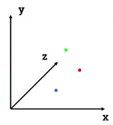
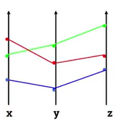


#### Structure of the Diagram

- Parallel coordinates present data in a specific style diagram
- The diagram consists of:
    * A number of parallel lines (axis), usually vertically oriented, corresponding to the dimension of the dataset
    * Multiple 'polylines', which cross each axis at points corresponding to the actual data points from the dataset
- Can represent both positive and negative values. Are there diagrams which cannot meaningfully represent negative values? (pie chart, radar?)
- Multidimensional datasets might contain widely different data types, as illustrated in previous examples. In the case of numerical values (ratios), the ranges of the data points can vary signifiantly
- Visualising dimensions with different ranges requires the data points to be normalised to a certain scale. The scale should be suitable for all dimensions from the dataset

#### Implementations

- Examples:
    1. Algebraic functions applied on random values
    2. Iris dataset, illustrating samples from 3 different plant species
- The examples will demonstrate how parallel coordinates can reveal information, which otherwise would not be obvious
    * As expected, it would be more difficult to follow indvidual values if the datasets have large number of samples
    * In cases of large datasets, parallel coordinates illustrate the overall trends of the samples, or, if no trends can be observed, the randomness of the data points

In [ ]:
# Example 1: Random Values

# We will use synthetically generated dataset

import numpy as np
import matplotlib.pyplot as plt

# -- Step 1: Declare variables for number of samples, scale, and array which will store the dataset

NumberOfSamples = int(50)
Scale = int(1000)
MyArray = np.empty(shape=(NumberOfSamples,3),dtype=int)

# -- Step 2: Initialize 3 dimensions of dataset by applying algebraic transformation on the random values

# Dimension 1: Random values
for i in range(0, NumberOfSamples):
    MyArray[i,0] = int(np.random.random()*Scale)
# print("Dim1", MyArray[:,0])

# Dimension 2: Equally spaced values
for i in range(0, NumberOfSamples):
    MyArray[i,1] = int(i*(Scale/NumberOfSamples))
# print("Dim2", MyArray[:,1])

# Dimension 3: Inverse the values around the middle of the scale
for i in range(0, NumberOfSamples):
    if MyArray[i,1] <= Scale/2:
        MyArray[i,2] = int(MyArray[i,1]+int(Scale/2))
    if MyArray[i,1] > Scale/2:
        MyArray[i,2] = int(MyArray[i,1]-int(Scale/2))
# print("Dim3", MyArray[:,2])


# -- Step 3: Prepare and draw the diagram

# Set with hexadecimal values used for the colors of the lines
k = ['0','1','2','3','4','5','6','7','8','9','A','B','C','D','E','F']
MyC = '#'

# The spines (axis) of the parallel coordinates
for i in range(0,3):
    plt.vlines(i, 0, Scale, '#808080')

# Draw the multi-lines with random colors
for i in range(0, NumberOfSamples):
    MyC = "#"
    for j in range(0,6):
        s = np.random.choice(k)
        MyC = MyC + s
    # print(MyC)
    plt.plot(list(range(3)), MyArray[i], color=MyC)
    # print(MyArray[i])

plt.xticks(list(range(0,3)))
plt.ylabel("Value")
plt.title("Parallel Coordinates Plot")
plt.tight_layout()
plt.show()


In [ ]:
# Example 2: Iris Dataset

# By following the same steps as the previous example, we can render the parallel coordinates

# We use solid colours of red, green, and blue for the 3 species
# The parallel coordinates allow us to identify features which can help classify the species

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

# -- Step 1: Load iris dataset and prepare variables

iris = load_iris()
NumberOfSamples = len(iris.data)
Scale = 1000
MyArray = np.empty(shape=(NumberOfSamples, 4), dtype=float)  # Use float for scaling

# -- Step 2: Populate MyArray with scaled feature values

# Normalize each feature to [0, 1]
X = iris.data
X_min = X.min(axis=0)
X_max = X.max(axis=0)
X_scaled = (X - X_min) / (X_max - X_min) * Scale
MyArray[:, :] = X_scaled
# print(MyArray)

# -- Step 3: Prepare and draw the diagram

# Set with values used for the colors of the lines
colors = ['red', 'green', 'blue']  # Setosa, Versicolor, Virginica
targets = iris.target

# Create a wide figure
plt.figure(figsize=(12, 6))

# The spines (axis) of the parallel coordinates
for i in range(0, 4):
    plt.vlines(i, 0, Scale, '#808080')

# Draw the multi-lines with fixed colors per category
for i in range(NumberOfSamples):
    plt.plot(list(range(4)), MyArray[i], color=colors[targets[i]], alpha=0.6)

plt.xticks(list(range(4)), iris.feature_names, rotation=30)
plt.yticks([])
plt.title("Parallel Coordinates Plot (Iris Dataset)")
plt.tight_layout()

# Add legend outside the plot (right side)
for i, name in enumerate(iris.target_names):
    plt.plot([], [], color=colors[i], label=name)
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

# Adjust layout
plt.tight_layout()
plt.show()


In [ ]:
### What can you observe from the parallel coordinates chart for the Iris dataset?
